# Notebook 02 — Hand Landmark Extraction
## American Sign Language (ASL) Detection
---
Reads each video, samples 30 evenly-spaced frames, runs MediaPipe Hands on every frame,
and saves `(30, 126)` landmark sequences. Then augments the training set 10x.

**Input shape:** `(30 frames, 126 values)` — 21 landmarks × 3 coords (x,y,z) × 2 hands

In [1]:
import os, json, pickle, urllib.request, warnings
import numpy as np
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt
from tqdm import tqdm
warnings.filterwarnings('ignore')

np.random.seed(42)
print(f'OpenCV {cv2.__version__}  |  MediaPipe {mp.__version__}')

OpenCV 4.13.0  |  MediaPipe 0.10.35


In [2]:
# Load metadata saved by Notebook 01
with open('processed_data/dataset_stats.json') as f:
    stats = json.load(f)
with open('processed_data/class_names.json') as f:
    class_names = json.load(f)

NUM_CLASSES  = stats['num_classes']
train_paths  = np.load('processed_data/train_paths.npy',  allow_pickle=True)
train_labels = np.load('processed_data/train_labels.npy')
val_paths    = np.load('processed_data/val_paths.npy',    allow_pickle=True)
val_labels   = np.load('processed_data/val_labels.npy')
test_paths   = np.load('processed_data/test_paths.npy',   allow_pickle=True)
test_labels  = np.load('processed_data/test_labels.npy')

print(f'Classes : {NUM_CLASSES}')
print(f'Train   : {len(train_paths)} videos')
print(f'Val     : {len(val_paths)} videos')
print(f'Test    : {len(test_paths)} videos')

Classes : 30
Train   : 589 videos
Val     : 150 videos
Test    : 150 videos


In [3]:
# Download MediaPipe model and set up HandLandmarker
from mediapipe.tasks.python.vision import HandLandmarker, HandLandmarkerOptions
from mediapipe.tasks.python.vision.hand_landmarker import HandLandmarksConnections
from mediapipe.tasks.python.vision import drawing_utils  as mp_drawing
from mediapipe.tasks.python.vision import drawing_styles as mp_draw_styles
from mediapipe.tasks.python.core.base_options import BaseOptions
from mediapipe.tasks.python.vision.core.vision_task_running_mode import VisionTaskRunningMode

HAND_CONNECTIONS = HandLandmarksConnections.HAND_CONNECTIONS
SEQUENCE_LENGTH  = 30
FEATURE_SIZE     = 126  # 21 landmarks x 3 coords x 2 hands
MODEL_FILE       = 'hand_landmarker.task'

if not os.path.exists(MODEL_FILE):
    print('Downloading hand_landmarker.task ...')
    urllib.request.urlretrieve(
        'https://storage.googleapis.com/mediapipe-models/hand_landmarker/'
        'hand_landmarker/float16/latest/hand_landmarker.task', MODEL_FILE)
    print('Done.')
else:
    print(f'Model file ready: {MODEL_FILE}')

def make_landmarker():
    opts = HandLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=MODEL_FILE),
        running_mode=VisionTaskRunningMode.IMAGE,
        num_hands=2,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
    )
    return HandLandmarker.create_from_options(opts)

# Save sequence config for later notebooks
with open('processed_data/sequence_config.json', 'w') as f:
    json.dump({'SEQUENCE_LENGTH': SEQUENCE_LENGTH,
               'FEATURE_SIZE': FEATURE_SIZE,
               'NUM_CLASSES': NUM_CLASSES}, f, indent=2)
print('Config saved.')

Model file ready: hand_landmarker.task
Config saved.


In [4]:
# Extraction helper functions
def get_frames(video_path, n=30):
    """Sample n evenly-spaced frames from a video."""
    cap = cv2.VideoCapture(video_path)
    total = max(int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), 1)
    indices = np.linspace(0, total - 1, n, dtype=int)
    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if ret:
            frames.append(frame)
        elif frames:
            frames.append(frames[-1])   # repeat last frame if read fails
        else:
            frames.append(np.zeros((224, 224, 3), np.uint8))
    cap.release()
    return frames

def frame_to_landmarks(frame_bgr, landmarker):
    """Extract 126-value landmark vector from one frame (zeros if no hand detected)."""
    rgb    = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    result = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    lm = np.zeros(FEATURE_SIZE, np.float32)
    for hi, hand in enumerate(result.hand_landmarks[:2]):
        off = hi * 63
        for li, l in enumerate(hand):
            lm[off + li*3], lm[off + li*3+1], lm[off + li*3+2] = l.x, l.y, l.z
    return lm

def video_to_sequence(path, landmarker):
    """Convert one video to a (30, 126) landmark sequence."""
    frames = get_frames(path, SEQUENCE_LENGTH)
    return np.stack([frame_to_landmarks(f, landmarker) for f in frames])

print('Extraction functions defined.')

Extraction functions defined.


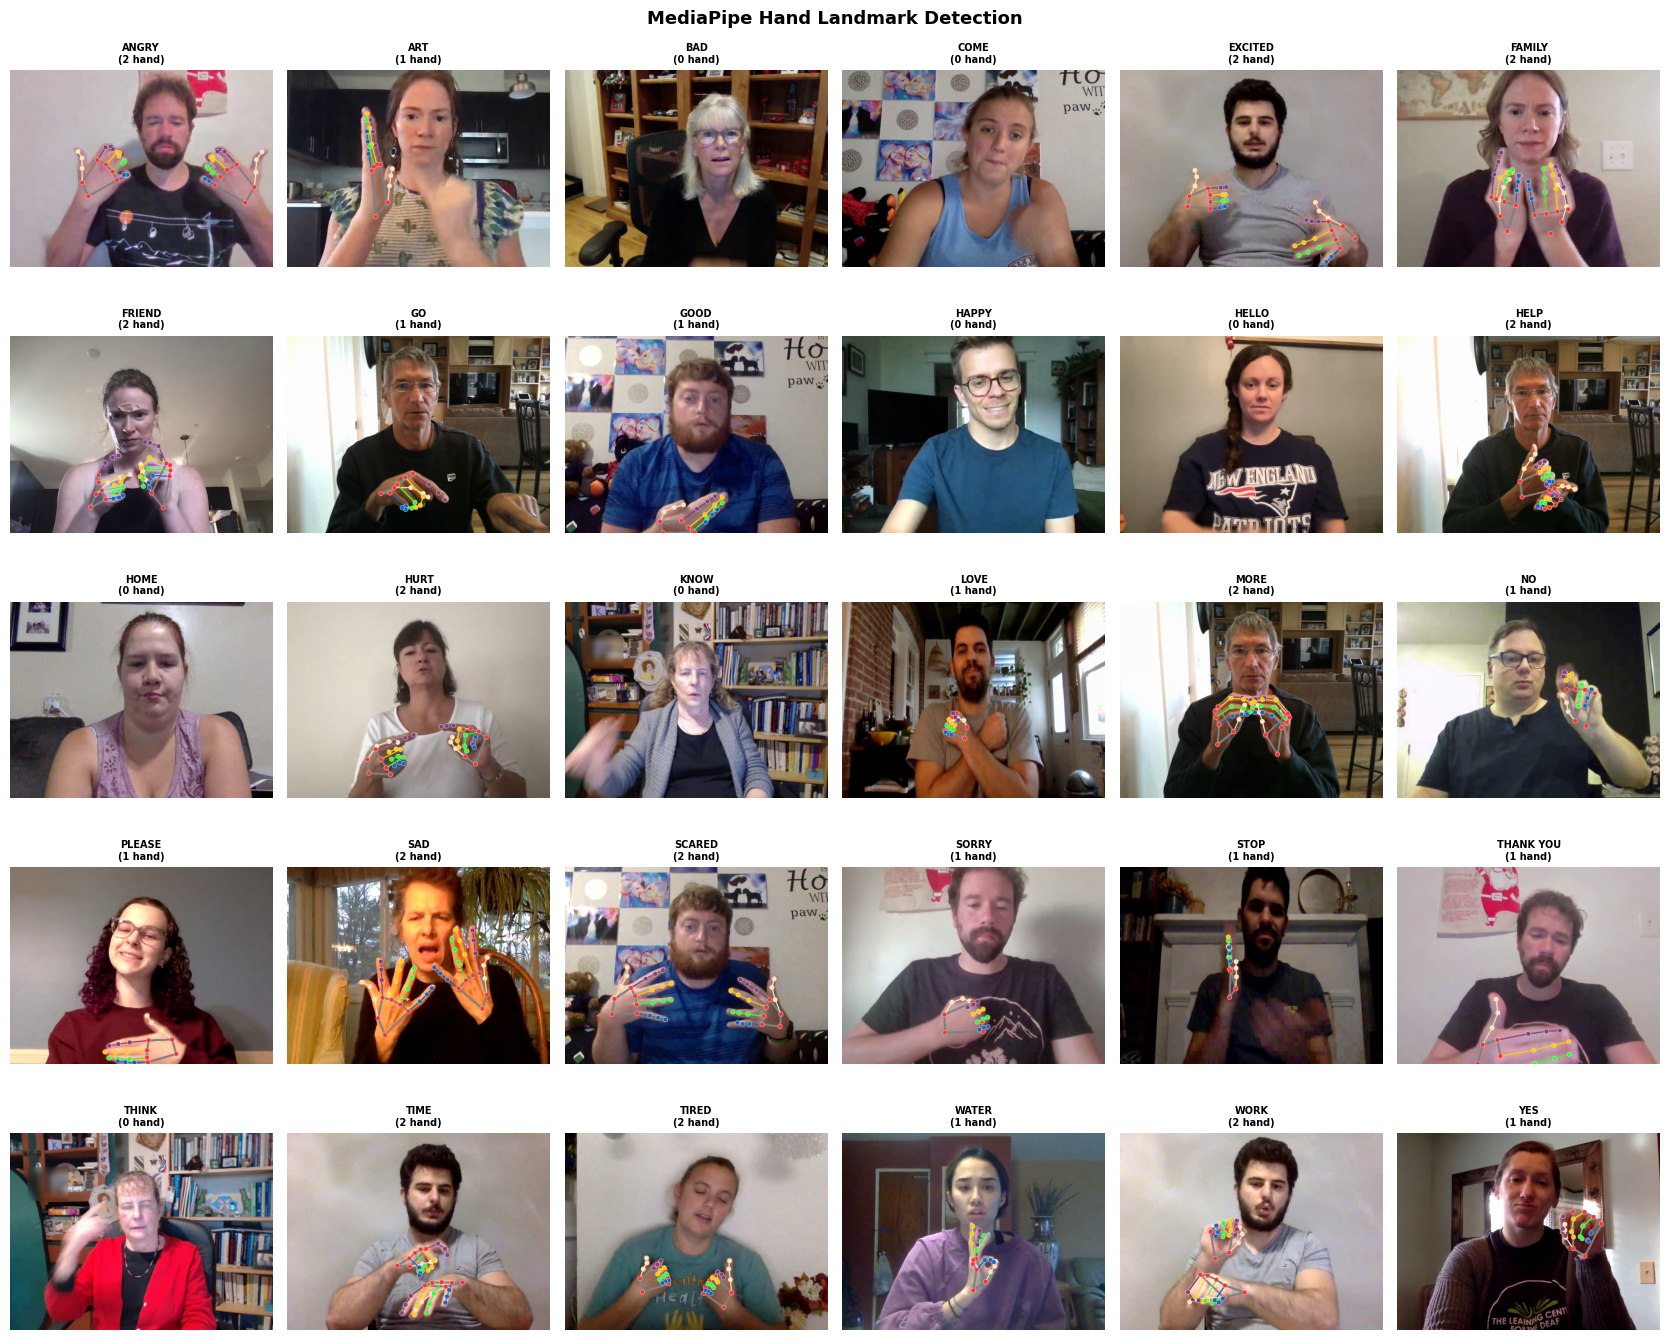

In [5]:
# Visualise MediaPipe landmark detection — one sample per class
all_paths_all  = list(train_paths) + list(val_paths) + list(test_paths)
all_labels_all = list(train_labels) + list(val_labels) + list(test_labels)

cols = 6
rows = (NUM_CLASSES + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.8, rows * 2.8))
axes = np.array(axes).flatten()

with make_landmarker() as landmarker:
    for cls_idx, cls_name in enumerate(class_names):
        vid_path = all_paths_all[next(i for i, l in enumerate(all_labels_all) if l == cls_idx)]
        mid_frame = get_frames(vid_path, 30)[15].copy()
        rgb = cv2.cvtColor(mid_frame, cv2.COLOR_BGR2RGB)
        result = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb.copy()))
        if result.hand_landmarks:
            for hand in result.hand_landmarks:
                mp_drawing.draw_landmarks(mid_frame, hand, HAND_CONNECTIONS,
                    mp_draw_styles.get_default_hand_landmarks_style(),
                    mp_draw_styles.get_default_hand_connections_style())
        axes[cls_idx].imshow(cv2.cvtColor(mid_frame, cv2.COLOR_BGR2RGB))
        detected = len(result.hand_landmarks) if result.hand_landmarks else 0
        axes[cls_idx].set_title(f'{cls_name}\n({detected} hand)', fontsize=7, fontweight='bold')
        axes[cls_idx].axis('off')

for j in range(NUM_CLASSES, len(axes)):
    axes[j].axis('off')

plt.suptitle('MediaPipe Hand Landmark Detection', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('processed_data/landmark_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Extract landmark sequences from all videos (~15 minutes)
def extract_split(paths, labels, split_name):
    X = np.zeros((len(paths), SEQUENCE_LENGTH, FEATURE_SIZE), np.float32)
    with make_landmarker() as landmarker:
        for i, path in enumerate(tqdm(paths, desc=split_name)):
            X[i] = video_to_sequence(path, landmarker)
    return X, np.array(labels, np.int32)

print('Extracting landmarks from all videos...')
X_train, y_train = extract_split(train_paths, train_labels, 'train')
X_val,   y_val   = extract_split(val_paths,   val_labels,   'val')
X_test,  y_test  = extract_split(test_paths,  test_labels,  'test')

print(f'\nShapes:')
print(f'  X_train: {X_train.shape}  y_train: {y_train.shape}')
print(f'  X_val  : {X_val.shape}  y_val  : {y_val.shape}')
print(f'  X_test : {X_test.shape}  y_test : {y_test.shape}')

Extracting landmarks from all videos...


test: 100%|██████████| 150/150 [01:48<00:00,  1.38it/s]


Shapes:
  X_train: (589, 30, 126)  y_train: (589,)
  X_val  : (150, 30, 126)  y_val  : (150,)
  X_test : (150, 30, 126)  y_test : (150,)


In [10]:
# Augment training data 10x: 9 transforms applied to every sample
# More training data = better accuracy for 30 classes
def augment_training(X, y):
    rng = np.random.default_rng(42)

    # Each fn receives a single sequence s of shape (30, 126)
    def noise(s):
        return np.clip(s + rng.normal(0, 0.006, s.shape).astype(np.float32), 0, 1)

    def hflip(s):
        out = s.copy()
        out[:, 0::3] = 1.0 - out[:, 0::3]   # mirror x-coordinates
        return out

    def scale(s):
        factor = rng.uniform(0.85, 1.15)
        out = s.copy()
        cx = out[:, 0::3].mean()
        cy = out[:, 1::3].mean()
        out[:, 0::3] = np.clip(cx + (out[:, 0::3] - cx) * factor, 0, 1)
        out[:, 1::3] = np.clip(cy + (out[:, 1::3] - cy) * factor, 0, 1)
        return out

    def translate(s):
        dx, dy = rng.uniform(-0.05, 0.05), rng.uniform(-0.05, 0.05)
        out = s.copy()
        out[:, 0::3] = np.clip(out[:, 0::3] + dx, 0, 1)
        out[:, 1::3] = np.clip(out[:, 1::3] + dy, 0, 1)
        return out

    transforms = [
        noise,
        hflip,
        lambda s: noise(hflip(s)),
        scale,
        lambda s: noise(scale(s)),
        translate,
        lambda s: noise(translate(s)),
        lambda s: hflip(scale(s)),
        lambda s: noise(hflip(translate(s))),
    ]

    aug_X = [X.copy()]
    aug_y = [y.copy()]
    for fn in transforms:
        aug_X.append(np.stack([fn(X[i]) for i in range(len(X))]))
        aug_y.append(y.copy())

    X_out = np.concatenate(aug_X)
    y_out = np.concatenate(aug_y)
    perm  = rng.permutation(len(X_out))
    return X_out[perm], y_out[perm]

X_train_aug, y_train_aug = augment_training(X_train, y_train)
print(f'Before augmentation : {X_train.shape}')
print(f'After  augmentation : {X_train_aug.shape}  ({len(X_train_aug) // len(X_train)}x)')

Before augmentation : (589, 30, 126)
After  augmentation : (5890, 30, 126)  (10x)


In [11]:
# Save all sequences
np.save('processed_data/X_train.npy', X_train_aug)
np.save('processed_data/y_train.npy', y_train_aug)
np.save('processed_data/X_val.npy',   X_val)
np.save('processed_data/y_val.npy',   y_val)
np.save('processed_data/X_test.npy',  X_test)
np.save('processed_data/y_test.npy',  y_test)

print('Saved sequences:')
for fname in ['X_train.npy','y_train.npy','X_val.npy','y_val.npy','X_test.npy','y_test.npy']:
    sz = os.path.getsize(f'processed_data/{fname}') // 1024
    print(f'  {fname:20s}  {sz:6} KB')
print('\nProceed to Notebook 03.')

Saved sequences:
  X_train.npy            86969 KB
  y_train.npy               23 KB
  X_val.npy               2214 KB
  y_val.npy                  0 KB
  X_test.npy              2214 KB
  y_test.npy                 0 KB

Proceed to Notebook 03.
